# 03 · Train and Validate the Field Detector
**Notebook 3 of 6:** brief tasks 3.1 (train, save weights to `model/`) and 3.2 (validate, save images with boxes).

### Model choice: YOLOv3, as the brief asks, with YOLO26n as a baseline
The brief says *"Use YOLO_V3 trained on the personal dataset"*, so **YOLOv3 is trained here**, through Ultralytics' `yolov3u.pt`. That is the original YOLOv3 Darknet-53 backbone and FPN neck with Ultralytics' anchor-free detection head, trained with exactly the same data and augmentation as everything else. The original Darknet build needs a C/CUDA compile and hand-edited `.cfg` files. `yolov3u` installs with `pip` and runs on Colab, a laptop or SageMaker unchanged.

To check that the brief's choice is a sound one, the **same split and settings** also train **YOLO26n**, a 2026 nano model about 40x smaller. Both are compared on the validation photos, and the shipped model is chosen by a rule fixed *before* the test photos are scored: **ship YOLOv3 (the brief's model) unless YOLO26n is clearly better on validation (mAP@0.5:0.95 more than 0.02 higher).** Notebook 05 then reports both on the unseen test photos.

| | YOLOv3 (`yolov3u`) | YOLO26n |
|---|---|---|
| backbone | Darknet-53 (2018) | 2026 nano backbone |
| parameters | ~103 M | ~2.4 M |
| role here | **the brief's model** | baseline: does a tiny modern model do as well? |

### Training settings, and why
| setting | value | reason |
|---|---|---|
| start weights | COCO-pretrained `yolov3u.pt` / `yolo26n.pt` | already know edges, shapes and text blocks, so 74 images are enough |
| `imgsz` | 1024 | fields are 12-22 px tall; at 640 the smallest would shrink to ~7 px |
| `fliplr` | 0 | a mirrored report is not a real report (names are always on the left) |
| `degrees`, `perspective`, `shear` | small (3°, 0.0003, 1°) | real photos are slightly tilted, never upside down |
| `hsv_*` | moderate | photos have blue, pink and grey colour casts |
| `mosaic` | on, off for the last 15 epochs | more variety early, realistic full pages at the end |
| `epochs` / `patience` | 100 / 40 | early stopping if validation stops improving |
| `batch` | YOLOv3: 2 on a 6 GB GPU, 8 on a 16 GB Colab T4; YOLO26n: 8 | GPU memory at 1024 px |

In [1]:
# --- 0. Paths: the same notebook runs in Google Colab (with Drive) or on a laptop ----------
import sys, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules              # True when running inside Colab
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # brief Task 1.1: mount Google Drive
    DRIVE = Path("/content/drive/MyDrive/Custom_OCR")  # datasets/, model/, results/ live here
    REPO = Path("/content/custom-ocr-lab-reports")     # the code (cloned from GitHub)
    if not REPO.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/SumeetRajput/custom-ocr-lab-reports.git", str(REPO)], check=True)
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)        # the OCR engine
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-r", str(REPO / "requirements.txt")])
else:
    here = Path.cwd().resolve()
    REPO = here.parent if here.name == "notebooks" else here   # repo root on a local machine
    DRIVE = REPO                                               # locally, "Drive" = the repo folder

sys.path[:0] = [str(REPO), str(REPO / "tools")]   # so we can import Custom_OCR and the tools
import Custom_OCR; Custom_OCR.find_tesseract()      # finds Tesseract even when it is not on PATH (Windows)
DATASETS = DRIVE / "datasets"                     # brief folder structure: datasets/
RAW = DATASETS / "raw"                            # the 100 report photos (kept out of GitHub: they show a patient's name)
MODEL_DIR = DRIVE / "model"                       # brief: "a folder named model" for the weights
RESULTS = DRIVE / "results"                       # brief: results/
for p in (DATASETS, RAW, MODEL_DIR, RESULTS):
    p.mkdir(parents=True, exist_ok=True)
print("Code  :", REPO)
print("Data  :", DATASETS)
print("Colab :", IN_COLAB)

Code  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main
Data  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets
Colab : False


In [2]:
# --- 1. Libraries -----------------------------------------------------------------------------
import shutil, json, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from ultralytics import YOLO
import viz, train as trainer
from privacy import redact
viz.style()
OUT = RESULTS / "03_training"; OUT.mkdir(parents=True, exist_ok=True)
DATA_YAML = DATASETS / "yolo" / "data.yaml"            # written by notebook 02
DEVICE = 0 if torch.cuda.is_available() else "cpu"     # Colab GPU if present
print("Device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

Device: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Part 1 · Train both detectors
Set `RETRAIN = True` to train from scratch. On the RTX 3050 laptop GPU (6 GB) used here, YOLOv3 took 47 minutes and YOLO26n 81 minutes (it shared the machine with the OCR tuning run); a Colab T4 is faster. With `False`, the notebook loads the logged runs that produced the committed weights, so every number below is reproducible without a GPU.

In [3]:
# --- 1.1 Train (or reuse the logged runs) ---------------------------------------------------
RETRAIN = False
big_gpu = DEVICE == 0 and torch.cuda.get_device_properties(0).total_memory > 10e9
DETECTORS = {"yolov3u": 8 if big_gpu else 2,      # the brief's YOLOv3 (Darknet-53)
             "yolo26n": 8}                        # modern nano baseline
RUNS = {}
for name, batch in DETECTORS.items():
    run = OUT / f"{name}_1024"
    if RETRAIN or not (run / "weights" / "best.pt").exists():
        run = trainer.train(DATA_YAML, epochs=100, batch=batch, device=DEVICE, weights=f"{name}.pt",
                            project=OUT, name=f"{name}_1024")
    else:   # logged run: copy its weights to model/ exactly as train() would
        shutil.copy(run / "weights" / "best.pt", MODEL_DIR / f"{name}_best.pt")
    RUNS[name] = run
    w = MODEL_DIR / f"{name}_best.pt"
    print(f"{name:8s} weights -> {w}  ({w.stat().st_size / 1e6:.1f} MB)")

yolov3u  weights -> C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\model\yolov3u_best.pt  (207.8 MB)
yolo26n  weights -> C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\model\yolo26n_best.pt  (5.5 MB)


## Part 2 · Learning curves
Two questions: did the losses fall (is the model learning?), and did *validation* accuracy rise with them (is it learning something that transfers)? Losses and accuracy have different scales, so they get separate charts rather than one twin-axis chart.

In [4]:
# --- 2.1 Read both training logs ------------------------------------------------------------
logs = {}
for name, run in RUNS.items():
    log = pd.read_csv(run / "results.csv"); log.columns = [c.strip() for c in log.columns]
    best = log.loc[log["metrics/mAP50-95(B)"].idxmax()]
    logs[name] = (log, best)
    print(f"{name:8s} epochs run {int(log.epoch.max()):3d} | best epoch {int(best.epoch):3d} | "
          f"val mAP50 {best['metrics/mAP50(B)']:.3f} | val mAP50-95 {best['metrics/mAP50-95(B)']:.3f}")

yolov3u  epochs run 100 | best epoch  92 | val mAP50 0.993 | val mAP50-95 0.818
yolo26n  epochs run 100 | best epoch  85 | val mAP50 0.995 | val mAP50-95 0.880


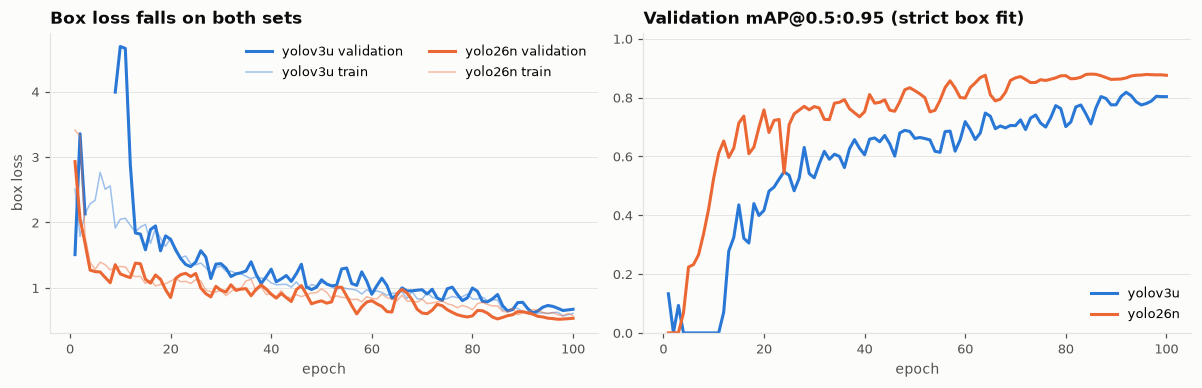

In [5]:
# --- 2.2 Plot losses and validation accuracy side by side ---------------------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (name, (log, best)) in enumerate(logs.items()):
    a1.plot(log.epoch, log["val/box_loss"], color=viz.SERIES[k], label=f"{name} validation")
    a1.plot(log.epoch, log["train/box_loss"], color=viz.SERIES[k], linewidth=1, alpha=0.45, label=f"{name} train")
    a2.plot(log.epoch, log["metrics/mAP50-95(B)"], color=viz.SERIES[k], label=name)
a1.set_title("Box loss falls on both sets"); a1.set_xlabel("epoch"); a1.set_ylabel("box loss"); a1.legend(ncol=2)
a2.set_ylim(0, 1.02); a2.set_title("Validation mAP@0.5:0.95 (strict box fit)"); a2.set_xlabel("epoch"); a2.legend(loc="lower right")
for a in (a1, a2): a.grid(axis="x", visible=False)
plt.tight_layout(); fig.savefig(OUT / "learning_curves.png"); plt.show()

**How to read mAP.** *mAP@0.5* asks "did the predicted box overlap the true box by at least 50%?" *mAP@0.5:0.95* averages stricter thresholds up to 95% overlap, so it rewards tight boxes. Tight boxes matter for OCR: a box that clips one digit turns 2.14 into 2.1.

## Part 3 · Validation (brief Task 3.1: "validate the model using a subset of data") and model choice

In [6]:
# --- 3.1 Per-class metrics on the validation photos, both detectors ------------------------
tables, summary = [], []
for name in DETECTORS:
    mdl = YOLO(str(MODEL_DIR / f"{name}_best.pt"))
    m = mdl.val(data=str(DATA_YAML), split="val", imgsz=1024, batch=2, device=DEVICE, plots=False, verbose=False)
    t = pd.DataFrame({"class": [mdl.names[i] for i in range(len(mdl.names))], "precision": m.box.p,
                      "recall": m.box.r, "mAP50": m.box.ap50, "mAP50-95": m.box.ap})
    t.loc[len(t)] = ["ALL", m.box.mp, m.box.mr, m.box.map50, m.box.map]
    t.insert(0, "detector", name); tables.append(t.round(3))
    summary.append({"detector": name, "params_M": round(sum(p.numel() for p in mdl.model.parameters()) / 1e6, 1),
                    "val_mAP50": round(float(m.box.map50), 3), "val_mAP50_95": round(float(m.box.map), 3)})
per_class = pd.concat(tables, ignore_index=True); per_class.to_csv(OUT / "val_metrics.csv", index=False)
summary = pd.DataFrame(summary).set_index("detector")
display(per_class)
summary

Ultralytics 8.4.188  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLOv3 summary (fused): 96 layers, 103,667,324 parameters, 0 gradients, 282.2 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 849.6±262.7 MB/s, size: 65.0 KB)


val: Scanning C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets\yolo\labels\val... 12 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12 1.1Kit/s 0.0s

val: New cache created: C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets\yolo\labels\val.cache


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.5it/s 3.9s

                   all         12        224      0.997          1      0.995      0.878


Speed: 2.0ms preprocess, 51.0ms inference, 0.0ms loss, 1.4ms postprocess per image


,detector,class,precision,recall,mAP50,mAP50-95
0,yolov3u,test_name,0.973,0.982,0.994,0.626
1,yolov3u,value,0.991,1.000,0.995,0.878
2,yolov3u,unit,0.991,1.000,0.995,0.917
3,yolov3u,reference_range,0.977,1.000,0.995,0.852
4,yolov3u,ALL,0.983,0.996,0.995,0.818
5,yolo26n,test_name,0.998,1.000,0.995,0.810
6,yolo26n,value,0.996,1.000,0.995,0.891
7,yolo26n,unit,0.997,1.000,0.995,0.906
8,yolo26n,reference_range,0.997,1.000,0.995,0.903
9,yolo26n,ALL,0.997,1.000,0.995,0.878


,params_M,val_mAP50,val_mAP50_95
detector,,,
yolov3u,103.7,0.995,0.818
yolo26n,2.5,0.995,0.878


### The decision rule, applied
Fixed before any test photo was scored: **ship the brief's YOLOv3 unless YOLO26n is more than 0.02 mAP@0.5:0.95 better on validation.** The chosen weights are copied to `model/best.pt`, which is what `Custom_OCR.py`, the web app and the Docker image load.

In [7]:
# --- 3.2 Choose the shipped detector ---------------------------------------------------------
gap = summary.loc["yolo26n", "val_mAP50_95"] - summary.loc["yolov3u", "val_mAP50_95"]
SHIP = "yolo26n" if gap > 0.02 else "yolov3u"
shutil.copy(MODEL_DIR / f"{SHIP}_best.pt", MODEL_DIR / "best.pt")
model = YOLO(str(MODEL_DIR / "best.pt"))
print(f"YOLO26n - YOLOv3 validation mAP50-95 gap = {gap:+.3f}  ->  shipping {SHIP} as model/best.pt")

YOLO26n - YOLOv3 validation mAP50-95 gap = +0.060  ->  shipping yolo26n as model/best.pt


## Part 4 · Validation images with boxes (brief Task 3.1: "upload validation results")
Predictions are drawn on each validation photo and saved to `results/03_training/val_predictions/`. **Patient details are redacted** before saving. Ultralytics' own mosaic previews (`train_batch*.jpg`) are not published, because they show unredacted photos.

12 images saved to C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\results\03_training\val_predictions


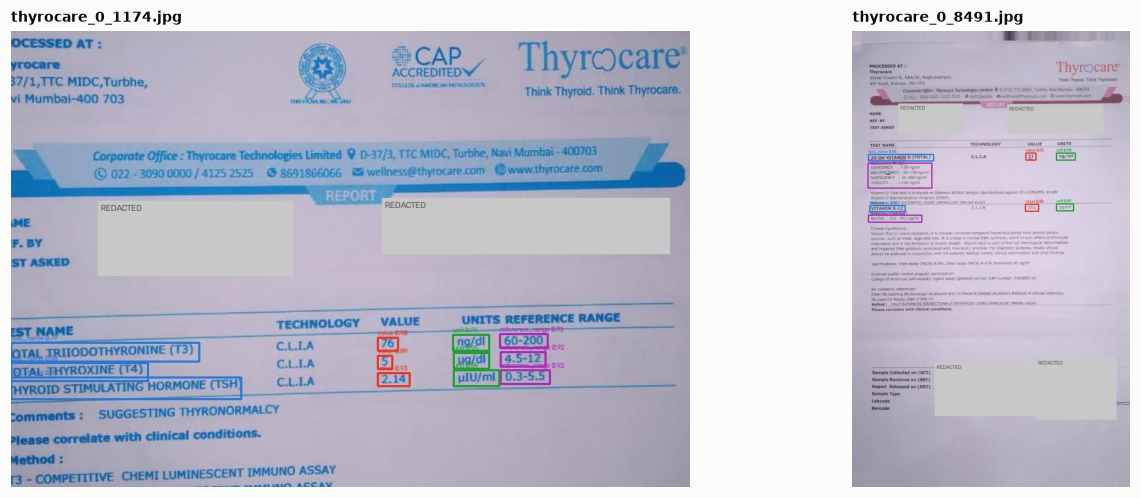

In [8]:
# --- 4.1 Draw and save -------------------------------------------------------------------------
import Custom_OCR as co
ann = json.load(open(DATASETS / "annotations.json", encoding="utf-8"))
vdir = OUT / "val_predictions"; shutil.rmtree(vdir, ignore_errors=True); vdir.mkdir()   # no stale images from an older split
val_imgs = sorted((DATASETS / "yolo" / "images" / "val").glob("*.jpg"))
for p in val_imgs:
    img = cv2.imread(str(p))
    dets = co.detect(model, img, conf=0.25)
    vis = co.draw(redact(img, ann[p.name]["redact"]), dets)
    cv2.imwrite(str(vdir / p.name), vis)
print(len(val_imgs), "images saved to", vdir)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, p in zip(axes, [val_imgs[0], val_imgs[-1]]):
    ax.imshow(cv2.cvtColor(cv2.imread(str(vdir / p.name)), cv2.COLOR_BGR2RGB)); ax.set_axis_off(); ax.set_title(p.name, fontsize=9)
plt.tight_layout(); plt.show()

In [9]:
# --- 4.2 Copy outputs to Drive when running in Colab -------------------------------------
if IN_COLAB:
    print("Weights and validation images are already under", DRIVE, "(Drive).")

## Summary
- **YOLOv3** (the brief's model, Darknet-53) and **YOLO26n** were both fine-tuned for up to 100 epochs at 1024 px on the same 74 training photos. Weights are in `model/yolov3u_best.pt` and `model/yolo26n_best.pt`; the shipped one is `model/best.pt`, chosen by the validation rule above.
- Validation metrics are high for both, which is expected: the validation photos show the same three report designs under different conditions. The test results in notebook 05 (both detectors, end to end through OCR) are the honest measurement.

**Mentor check**
1. Why is `fliplr=0` important here when it is on by default for most datasets?
2. What would a falling *train* loss with a rising *validation* loss tell you?
3. YOLOv3 has ~40x more parameters than YOLO26n. Why might that *not* translate into better boxes on this dataset?

**Next → Notebook 04:** crop, clean and read the fields, then write the CSV.